# A simple flat-top inverse design with incoherent illumination

We shape light from a Gaussian angular source into a smooth rectangular flat-top on a monitor at $z_2=1\,\mathrm m$. The source and pupil amplitude stay fixed while we optimize the phase. Equation (24) from the paper provides the monitor irradiance.


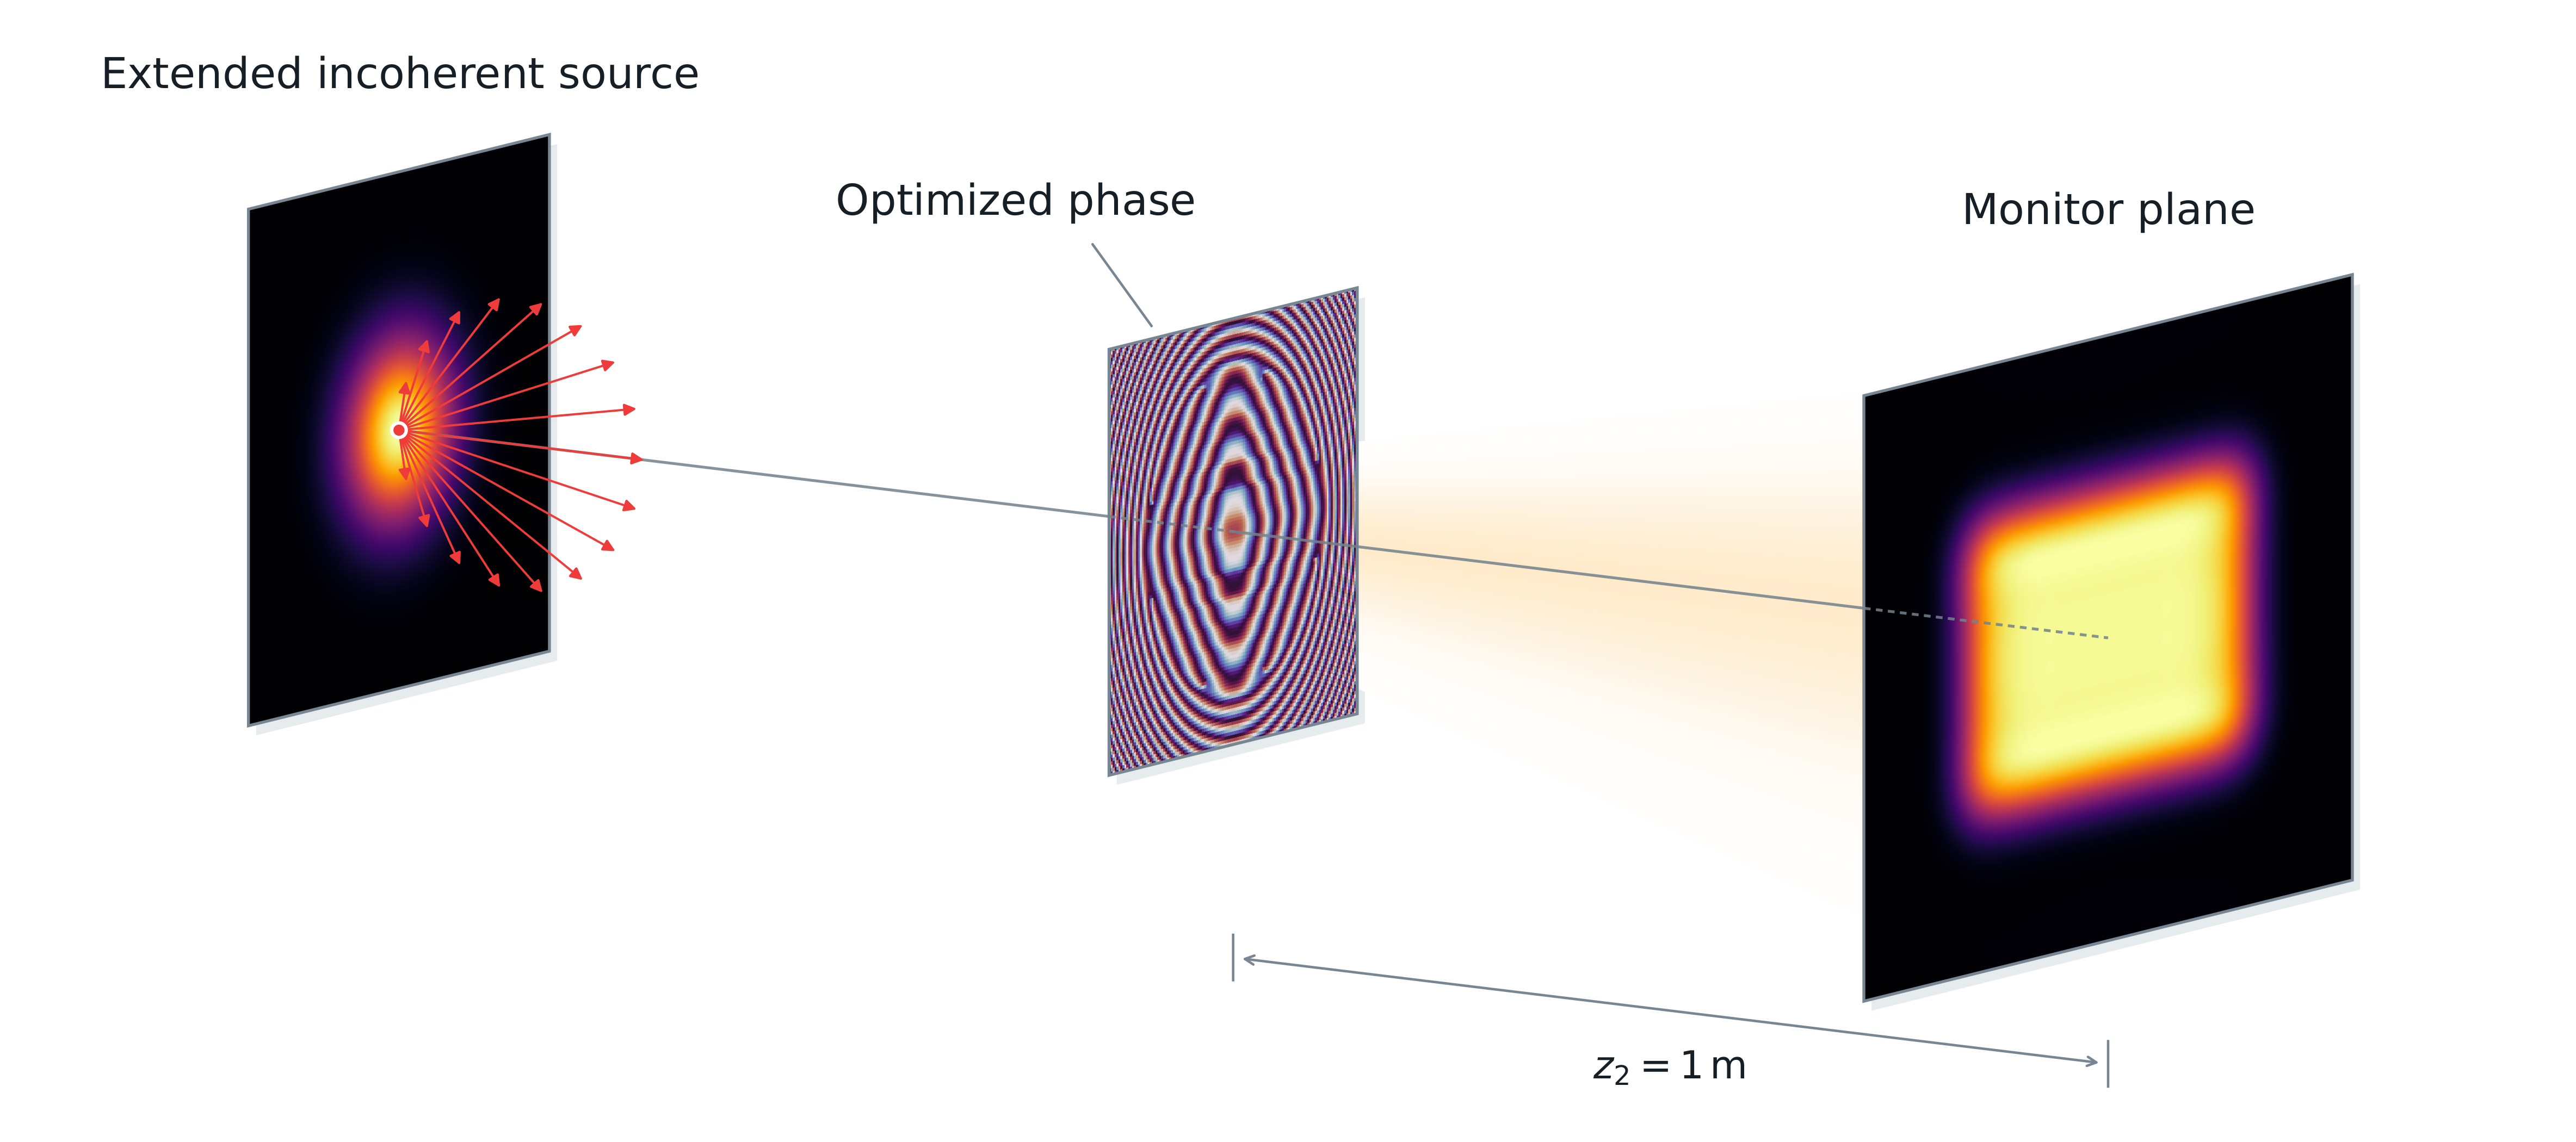

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
from jax.example_libraries import optimizers

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import IncoherentLightSimulation, ApertureFromFunction, m, mm, um, nm
from diffractsim.util.backend_functions import backend as bd

plt.rcParams["figure.dpi"] = 140

## 1. Define the source

The illumination contains mutually incoherent directions centered on the optical axis. We describe their radiance by

$$
L_{\mathrm{in}}(\alpha',\beta')=
\frac{E_{\mathrm{in}}}{2\pi\sigma^2}
\exp\!\left[-\frac{(\alpha')^2+(\beta')^2}{2\sigma^2}\right],
$$

with $\sigma=0.012$ and incident irradiance $E_{\mathrm{in}}=1\,\mathrm{W\,m^{-2}}$. This finite source width smooths the diffraction pattern. We use $\lambda=532\,\mathrm{nm}$ and a $128\times128$ pupil grid.

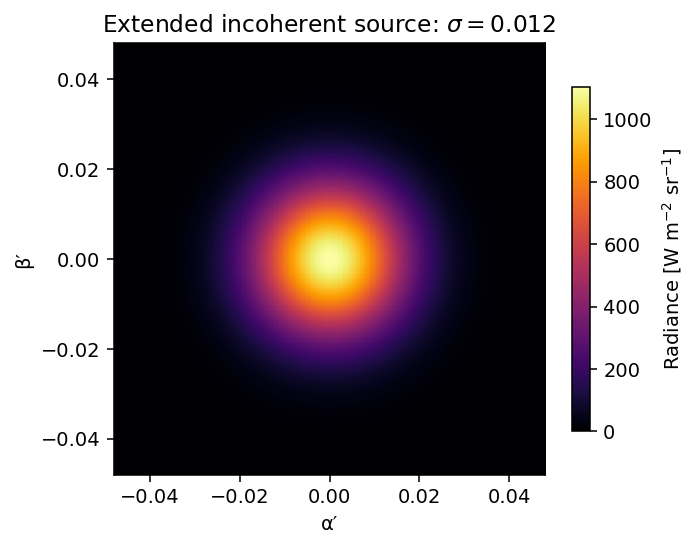

In [3]:
# 1. Define and plot the Gaussian angular source.
wavelength, N = 940*nm, 128
pixel = 1.2*wavelength
extent = N*pixel
sigma, incident_irradiance = 0.012, 1.0
z2 = 1*m

sim = IncoherentLightSimulation(wavelength, extent, extent, N, N)

def angular_source(alpha, beta):
    """Incoherent extended gaussian radiance, normalized to the incident pupil irradiance."""
    return incident_irradiance*bd.exp(-(alpha**2+beta**2)/(2*sigma**2))/(2*bd.pi*sigma**2)

sim.set_angular_illumination(angular_source, paraxial=False, angular_samples=1024)



fig, ax = plt.subplots(figsize=(5, 4))
sim.plot_source_radiance(xlim=(-4*sigma, 4*sigma), ylim=(-4*sigma, 4*sigma),ax=ax, title=rf"Extended incoherent source: $\sigma={sigma:g}$")
plt.show()

## 2. Choose the aperture and starting phase

The pupil transmission is

$$
\mathscr P(\xi,\eta)=A(\xi,\eta)e^{i\phi(\xi,\eta)},
\qquad
A(\xi,\eta)=\exp\!\left[-\frac{\xi^2+\eta^2}{w^2}\right],
$$

where $w=18\,\mu\mathrm m$. We start with a diverging quadratic phase, stronger horizontally than vertically, to spread the light toward the rectangular target. A small, reproducible random perturbation breaks the symmetry. Only the phase changes during optimization.

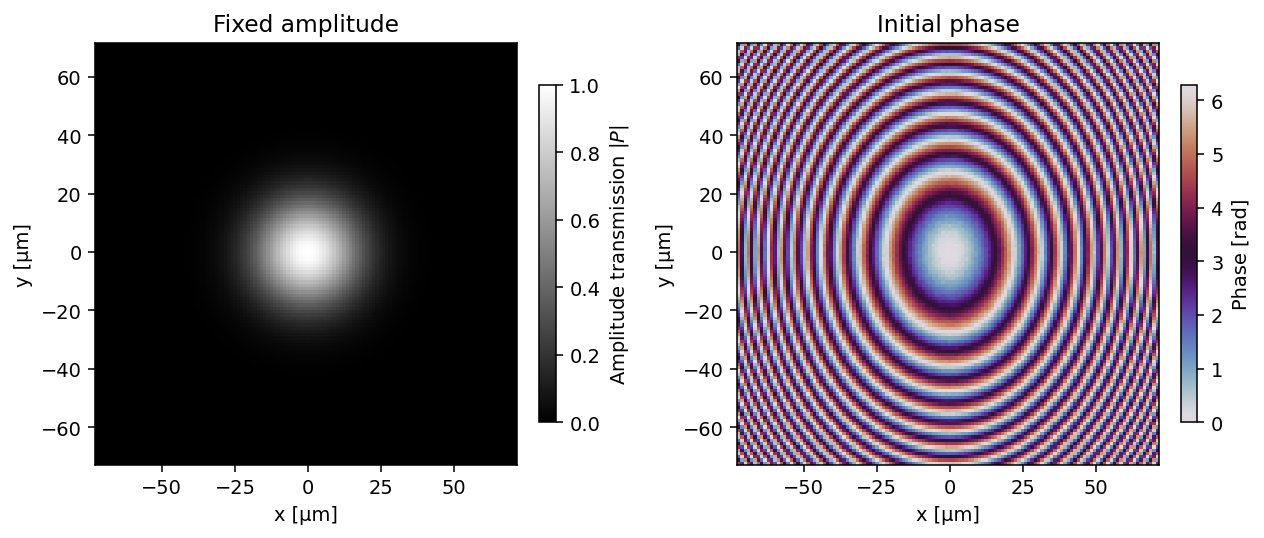

In [4]:
# 2. Define and plot the fixed amplitude and initial phase.
waist = 18*um
xx, yy = sim.xx, sim.yy
amplitude = bd.exp(-(xx**2+yy**2)/waist**2)

rng = np.random.default_rng(2)
phi_initial = bd.pi/wavelength*(0.07/waist*xx**2+0.045/waist*yy**2)
phi_initial += 0.04*bd.asarray(rng.normal(size=(N, N)))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout="constrained")
sim.plot_aperture(amplitude, units=um, ax=axes[0], title="Fixed amplitude")
sim.plot_aperture(amplitude*bd.exp(1j*phi_initial), phase=True, units=um, ax=axes[1], title="Initial phase")
plt.show()

## 3. Define the target on the monitor

We want a flat central region with smooth edges. In physical monitor coordinates, its shape is

$$
g(x,y)=\exp\!\left[-2\left(\frac{x}{w_x}\right)^8
                         -2\left(\frac{y}{w_y}\right)^8\right],
\qquad
T(x,y)=\frac{P_0\,g(x,y)}{\displaystyle\iint_{\mathcal A}g\,\mathrm dA},
$$

with $w_x=120\,\mathrm{mm}$ and $w_y=75\,\mathrm{mm}$. Here $\mathcal A$ is the monitor window and $P_0=E_{\mathrm{in}}\iint A^2\,\mathrm d\xi\,\mathrm d\eta$ is the power transmitted by the fixed Gaussian amplitude. This sets the target's absolute irradiance. The monitor includes $y=0$ for the final profile comparison; plots use $\mathrm{nW\,m^{-2}}$ to keep the values easy to read.

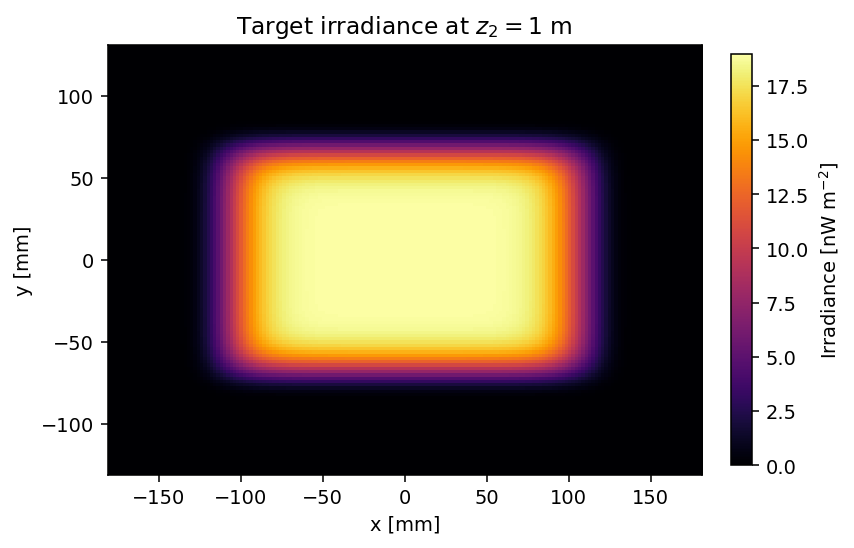

In [5]:
# 3. Define and plot the target irradiance at z2.
monitor_x = np.linspace(-180*mm, 180*mm, 181)
monitor_y = np.linspace(-130*mm, 130*mm, 131)
half_width_x, half_width_y = 120*mm, 75*mm
screen_x, screen_y = bd.meshgrid(monitor_x, monitor_y)
pixel_area = (monitor_x[1]-monitor_x[0])*(monitor_y[1]-monitor_y[0])

power_target = incident_irradiance*bd.sum(amplitude**2)*pixel**2
target_shape = bd.exp(-2*(screen_x/half_width_x)**8-2*(screen_y/half_width_y)**8)
target = power_target*target_shape/(bd.sum(target_shape)*pixel_area)
irradiance_units = 1e-9  # Display irradiance in nW/m².

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
sim.plot_map(monitor_x, monitor_y, target/irradiance_units, units=mm, ax=ax,
    labels=("x [mm]", "y [mm]"), colorbar_label=r"Irradiance [nW m$^{-2}$]",
    title=rf"Target irradiance at $z_2={z2/m:g}$ m", cmap="inferno", vmin=0)
plt.show()

## 4. Optimize the phase

For each trial phase, `forward` applies the pupil and evaluates Eq. (24) at $z_2$. The coherent response uses the angular Fresnel approximation, which retains the direction-cosine mapping and monitor weighting. We minimize the relative squared irradiance error over the monitor:

$$
\mathcal L(\phi)=
\frac{\displaystyle\iint_{\mathcal A}[E_\phi(x,y;z_2)-T(x,y)]^2\,\mathrm dA}
     {\displaystyle\iint_{\mathcal A}T(x,y)^2\,\mathrm dA}.
$$

The uniform pixel area cancels in this ratio. JAX computes the phase gradient, and Adam takes 350 steps. The two plots show the loss history and the resulting phase.

Relative squared error: 1.193987 → 0.002928
Loss reduction: 99.75%


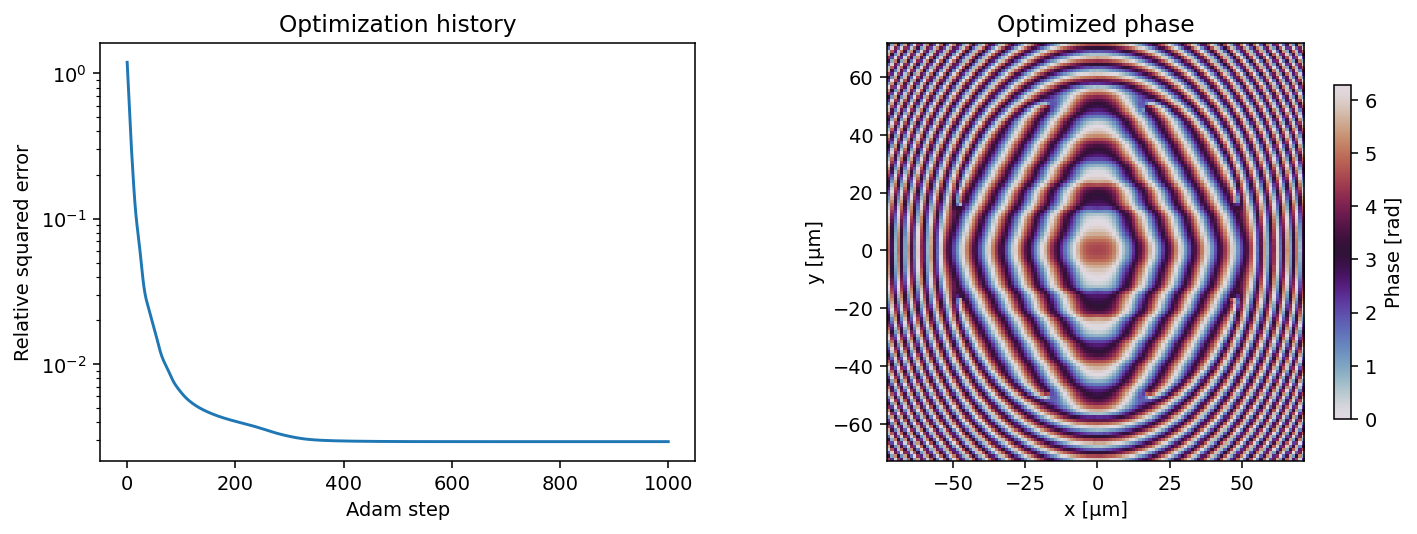

In [6]:
# 4. Define the optical model and loss, then optimize the phase.
iterations, learning_rate = 1000, 0.08

def forward(phi):
    """Return the irradiance on the monitor for this pupil phase."""
    plate = ApertureFromFunction(lambda x, y, wl: amplitude*bd.exp(1j*phi))

    def optical_setup(F, z):
        F = F.add(plate)
        return F.zoom_propagate(z,
            x_interval=[monitor_x[0], monitor_x[-1]],
            y_interval=[monitor_y[0], monitor_y[-1]],
            Nx_mon=len(monitor_x), Ny_mon=len(monitor_y),
            model="Fresnel", sampling="angular")

    return sim.get_irradiance(optical_setup, z2)[2]

def objective(phi):
    return bd.sum((forward(phi)-target)**2)/bd.sum(target**2)

opt_init, opt_update, get_params = optimizers.adam(step_size=learning_rate)

@jax.jit
def step(i, state):
    loss, gradient = jax.value_and_grad(objective)(get_params(state))
    return opt_update(i, gradient, state), loss

state, history = opt_init(phi_initial), []
for i in range(iterations):
    state, loss = step(i, state)
    history.append(float(loss))

phi_optimized = get_params(state)
final_loss = float(objective(phi_optimized))
history.append(final_loss)
print(f"Relative squared error: {history[0]:.6f} → {final_loss:.6f}")
print(f"Loss reduction: {100*(1-final_loss/history[0]):.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].semilogy(history)
axes[0].set(xlabel="Adam step", ylabel="Relative squared error", title="Optimization history")
sim.plot_aperture(amplitude*bd.exp(1j*phi_optimized), phase=True, units=um,
    ax=axes[1], title="Optimized phase")
plt.show()

## 5. Inspect the optimized irradiance

We evaluate the optimized phase with the same `forward` function used during optimization. The map shows the irradiance on the monitor, and the horizontal cut at $y=0$ compares it with the target. Both use the absolute irradiance scale defined above.

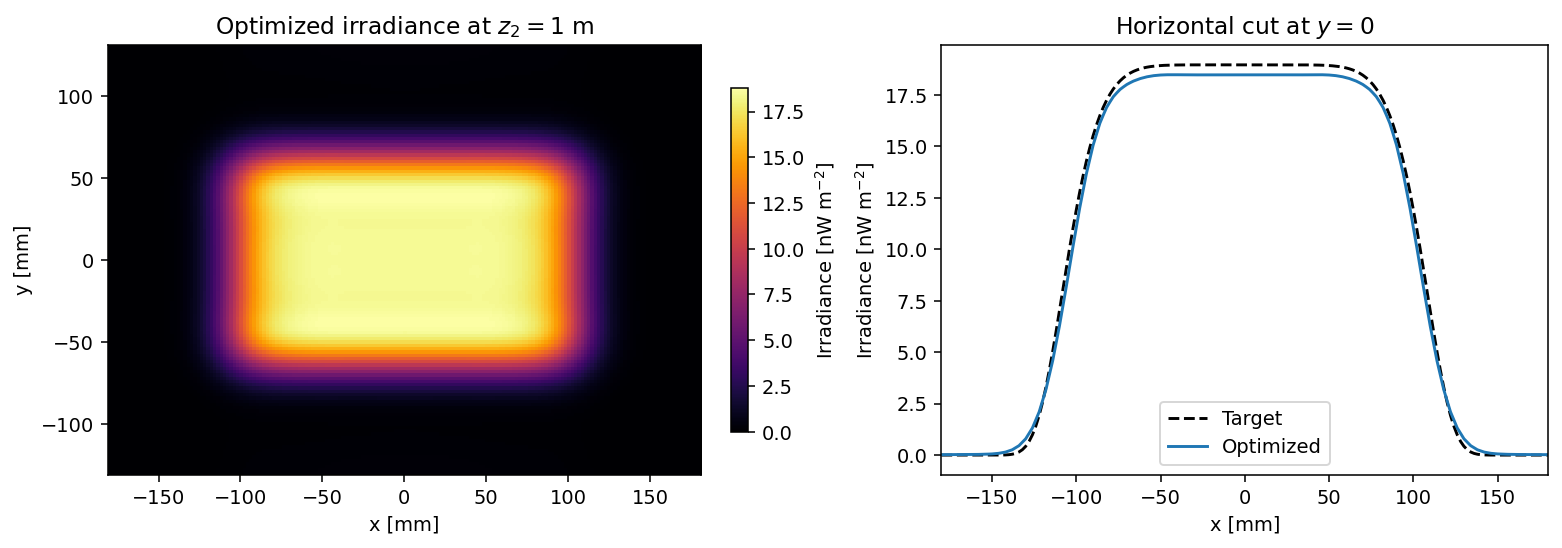

In [7]:
# 5. Simulate the optimized pupil and compare its central profile with the target.
optimized_E = forward(phi_optimized)
row = len(monitor_y)//2  # The symmetric, odd-sized grid includes y = 0.

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
sim.plot_map(monitor_x, monitor_y, optimized_E/irradiance_units, units=mm, ax=axes[0],labels=("x [mm]", "y [mm]"), colorbar_label=r"Irradiance [nW m$^{-2}$]",title=rf"Optimized irradiance at $z_2={z2/m:g}$ m", cmap="inferno", vmin=0)

axes[1].plot(monitor_x/mm, np.asarray(target[row]/irradiance_units), "k--", label="Target")
axes[1].plot(monitor_x/mm, np.asarray(optimized_E[row]/irradiance_units), label="Optimized")
axes[1].set(xlabel="x [mm]", ylabel=r"Irradiance [nW m$^{-2}$]",
    title=r"Horizontal cut at $y=0$", xlim=(monitor_x[0]/mm, monitor_x[-1]/mm))
axes[1].legend()
plt.show()

## 6. Check the optimized phase with full RS propagation

The optimization used Eq. (24). We now keep $\phi_{\mathrm{optimized}}$ fixed and evaluate the RS reference Eq. (25). on the same monitor.


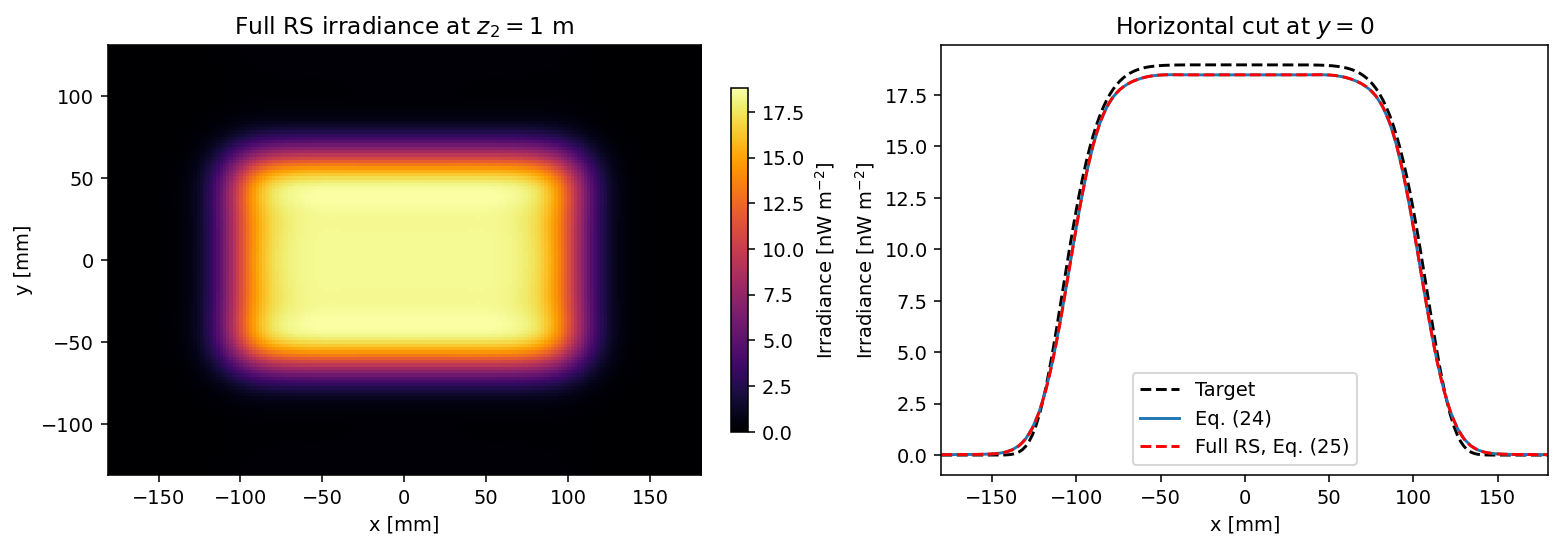

In [8]:
plate = ApertureFromFunction(lambda x, y, wl: amplitude*bd.exp(1j*phi_optimized))

def optical_setup(F, z):
    F = F.add(plate)
    return F.zoom_propagate(z,
        x_interval=[monitor_x[0], monitor_x[-1]],
        y_interval=[monitor_y[0], monitor_y[-1]],
        Nx_mon=len(monitor_x), Ny_mon=len(monitor_y),
        model="Fresnel", sampling="angular")

# 6. Verify the optimized pupil with the full outgoing RS kernel.
rs_E = sim.get_irradiance_rs(optical_setup, z2)[2]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
sim.plot_map(monitor_x, monitor_y, rs_E/irradiance_units, units=mm, ax=axes[0],
    labels=("x [mm]", "y [mm]"), colorbar_label=r"Irradiance [nW m$^{-2}$]",
    title=rf"Full RS irradiance at $z_2={z2/m:g}$ m", cmap="inferno", vmin=0)

axes[1].plot(monitor_x/mm, np.asarray(target[row]/irradiance_units), "k--", label="Target")
axes[1].plot(monitor_x/mm, np.asarray(optimized_E[row]/irradiance_units), label="Eq. (24)")
axes[1].plot(monitor_x/mm, np.asarray(rs_E[row]/irradiance_units), "r--", label="Full RS, Eq. (25)")
axes[1].set(xlabel="x [mm]", ylabel=r"Irradiance [nW m$^{-2}$]",
    title=r"Horizontal cut at $y=0$", xlim=(monitor_x[0]/mm, monitor_x[-1]/mm))
axes[1].legend()
plt.show()
